# Thống Kê Dữ Liệu Cào Bài Báo arXiv (Project Milestone 1)

Notebook này phục vụ báo cáo **Jupyter Book** cho Milestone 1 — Data Crawling thuộc môn học Nhập môn Khoa học Dữ liệu (HCMUS).

Nội dung tập trung giải quyết **2 bài toán thống kê cốt lõi**:
1. **Kích thước trung bình (bytes) của bài báo trước và sau khi loại bỏ hình ảnh.**
2. **Số lượng references trung bình mỗi bài, tỉ lệ crawl metadata references thành công.**

Đồng thời, notebook thực hiện **so sánh đối chiếu** kết quả thu được giữa 2 phương pháp cào (ưu tiên hiển thị phương pháp `arxiv_crawler` trước):
- **Phương pháp 1**: `arxiv_crawler` (Sử dụng arXiv API Python client).
- **Phương pháp 2**: `oai_crawler` (Sử dụng giao thức chuẩn OAI-PMH).

In [8]:
import sys
from pathlib import Path

# Nạp module statistic (hỗ trợ cả khi chạy từ thư mục root hoặc thư mục src)
src_dir = Path.cwd() / "src" if (Path.cwd() / "src").exists() else Path.cwd()
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

import statistic as stat
import pandas as pd
import matplotlib.pyplot as plt

print("Module statistic đã sẵn sàng!")

Module statistic đã sẵn sàng!


## 1. Nạp và Tổng hợp Dữ liệu Cào

Thu thập các chỉ số từ thư mục kết quả của 2 crawler: `./sourcesArxiv` và `./sourcesOAI`.

In [9]:
# Xác định đường dẫn thư mục cào
dir_arxiv = Path("../sourcesArxiv") if Path("../sourcesArxiv").exists() else Path("./sourcesArxiv")
dir_oai = Path("../sourcesOAI") if Path("../sourcesOAI").exists() else Path("./sourcesOAI")

# Quét và thu thập metrics từ metadata.json và references.json (ưu tiên arxiv_crawler trước)
df_arxiv = stat.collect_crawl_metrics(dir_arxiv, crawler_name="arxiv_crawler")
df_oai = stat.collect_crawl_metrics(dir_oai, crawler_name="oai_crawler")

print(f"-> [Ưu tiên] arXiv API crawler: {len(df_arxiv)} phiên bản bài báo ghi nhận.")
print(f"->          OAI-PMH crawler  : {len(df_oai)} phiên bản bài báo ghi nhận.")

# Xem mẫu 5 dòng dữ liệu đầu tiên (ưu tiên arxiv_crawler)
sample_df = df_arxiv if not df_arxiv.empty else df_oai
if not sample_df.empty:
    display(stat.format_table(sample_df.head()))
else:
    print("Chưa có dữ liệu cào. Hãy chạy crawler để sinh dữ liệu trước khi chạy tiếp các bước bên dưới.")

-> [Ưu tiên] arXiv API crawler: 82 phiên bản bài báo ghi nhận.
->          OAI-PMH crawler  : 82 phiên bản bài báo ghi nhận.


,crawler,paper_id,version,arxiv_id,title,source_status,raw_archive_bytes,total_uncompressed_bytes,filtered_uncompressed_bytes,bytes_saved,reduction_percent,references_status,references_count,arxiv_references_count
0,arxiv_crawler,2510.10788,v1,2510.10788v1,A formalism for giant Goos-Hänchen shift in metasurface sensors with phase singularity,downloaded,940632,1156389,121573,1034816,89.486842,success,31,3
1,arxiv_crawler,2510.10788,v2,2510.10788v2,A formalism for giant Goos-Hänchen shift in metasurface sensors with phase singularity,downloaded,1158596,1296843,116733,1180110,90.998679,success,31,3
2,arxiv_crawler,2510.10789,v1,2510.10789v1,Dual Band Receiver Design for the Black Hole Explorer (BHEX) Mission,no_tex_or_bib,478458,0,0,0,0.000000,success,13,10
3,arxiv_crawler,2510.10790,v1,2510.10790v1,BioOSS: A Bio-Inspired Oscillatory State System with Spatio-Temporal Dynamics,downloaded,679867,1089242,118215,971027,89.147040,success,37,19
4,arxiv_crawler,2510.10791,v1,2510.10791v1,A compressed code for memory discrimination,no_tex_or_bib,0,0,0,0,0.000000,success,259,30


## 2. Thống kê Kích Thước Bài Báo Trước và Sau Khi Loại Bỏ Hình Ảnh

Theo yêu cầu đồ án, việc loại bỏ hình ảnh (chỉ giữ lại các file `.tex` và `.bib`) nhằm tối ưu không gian lưu trữ và chuẩn bị cho cây phân cấp ở Milestone 2.

- **Trước khi lọc**: Tổng dung lượng giải nén của toàn bộ file có trong tarball (bao gồm hình ảnh `.png`, `.jpg`, `.pdf`, mã nguồn `.tex`, `.bib`, file cấu hình...).
- **Sau khi lọc**: Tổng dung lượng chỉ bao gồm các file `.tex` và `.bib` được lưu lại.

In [10]:
# Bảng số liệu thống kê kích thước (Ưu tiên arXiv API trước, sau đó là OAI-PMH)
if not df_arxiv.empty:
    print("=== BẢNG THỐNG KÊ KÍCH THƯỚC (ARXIV API CRAWLER) ===")
    display(stat.format_table(stat.compute_paper_size_stats(df_arxiv)))

if not df_oai.empty:
    print("\n=== BẢNG THỐNG KÊ KÍCH THƯỚC (OAI-PMH CRAWLER) ===")
    display(stat.format_table(stat.compute_paper_size_stats(df_oai)))

=== BẢNG THỐNG KÊ KÍCH THƯỚC (ARXIV API CRAWLER) ===


,Chỉ số,Giá trị
0,Số lượng phiên bản bài báo (N),82
1,Kích thước trung bình trước khi lọc (Bytes),"2,610,558.50"
2,Kích thước trung bình trước khi lọc (KB),"2,549.37 KB"
3,Kích thước trung vị trước khi lọc (KB),387.59 KB
4,Kích thước trung bình sau khi lọc (Bytes),"687,652.17"
5,Kích thước trung bình sau khi lọc (KB),671.54 KB
6,Kích thước trung vị sau khi lọc (KB),84.70 KB
7,Dung lượng trung bình tiết kiệm được (KB),"1,877.84 KB"
8,Tỷ lệ giảm trung bình (%),57.94%
9,Tỷ lệ giảm trung vị (%),80.25%



=== BẢNG THỐNG KÊ KÍCH THƯỚC (OAI-PMH CRAWLER) ===


,Chỉ số,Giá trị
0,Số lượng phiên bản bài báo (N),82
1,Kích thước trung bình trước khi lọc (Bytes),"3,212,164.66"
2,Kích thước trung bình trước khi lọc (KB),"3,136.88 KB"
3,Kích thước trung vị trước khi lọc (KB),509.56 KB
4,Kích thước trung bình sau khi lọc (Bytes),"694,073.49"
5,Kích thước trung bình sau khi lọc (KB),677.81 KB
6,Kích thước trung vị sau khi lọc (KB),86.73 KB
7,Dung lượng trung bình tiết kiệm được (KB),"2,459.07 KB"
8,Tỷ lệ giảm trung bình (%),61.56%
9,Tỷ lệ giảm trung vị (%),81.82%


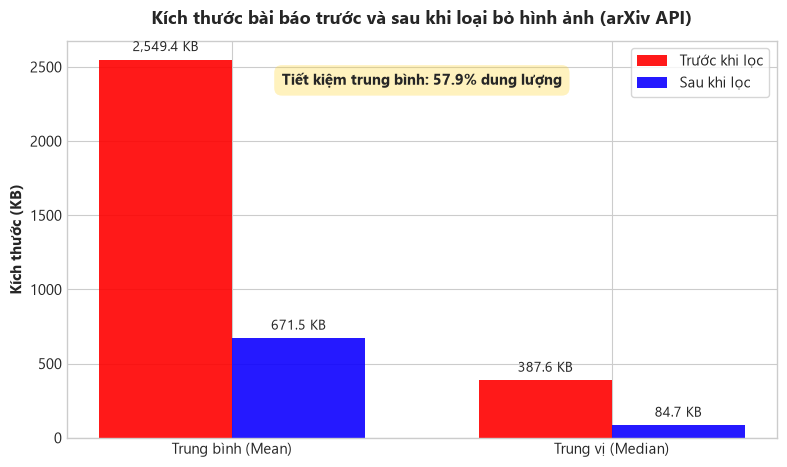

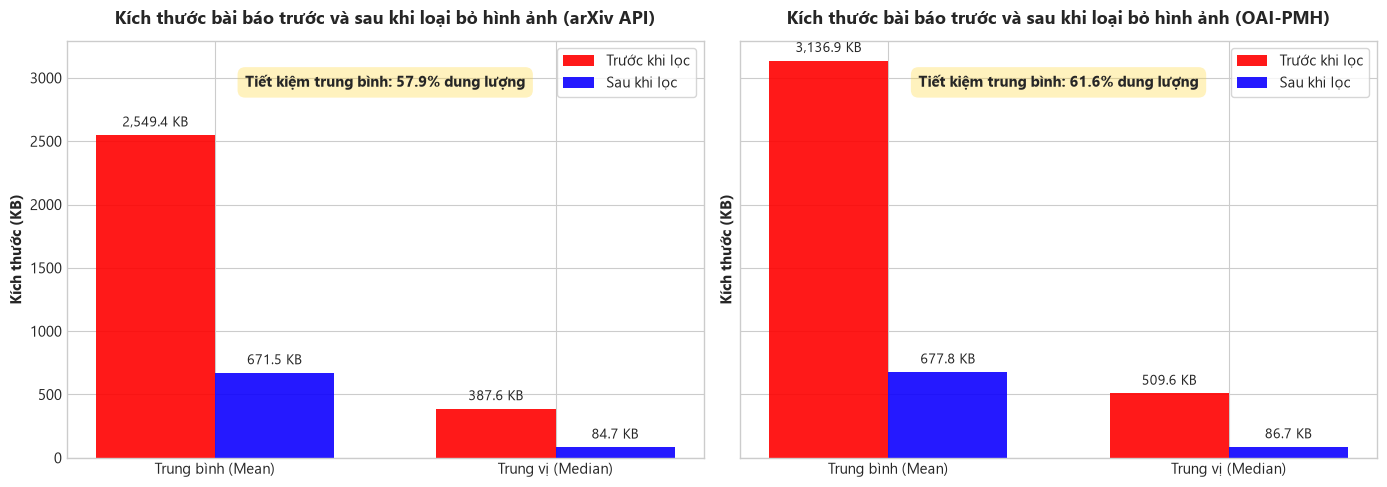

In [11]:
# Trực quan hóa so sánh kích thước trước vs sau lọc (Cột ghép: Đỏ đậm và Xanh dương đậm)
if not df_arxiv.empty:
    fig, ax = plt.subplots(figsize=(8, 4.8))
    stat.plot_size_comparison(df_arxiv, title_suffix="arXiv API", ax=ax)
    plt.show()

if not df_arxiv.empty and not df_oai.empty:
    fig = stat.plot_side_by_side_size(df_arxiv, df_oai)
    plt.show()

## 3. Thống Kê References và Tỷ Lệ Crawl Thành Công

Metadata về trích dẫn (references) được thu thập từ Semantic Scholar API. Chỉ số thống kê bao gồm:
- **Số lượng references trung bình** mỗi bài báo (Mean & Median).
- **Tỉ lệ crawl metadata references thành công** (`success_rate = bài thành công / tổng số bài`).

In [12]:
# Bảng số liệu thống kê References (Ưu tiên arXiv API trước, sau đó là OAI-PMH)
if not df_arxiv.empty:
    print("=== BẢNG THỐNG KÊ REFERENCES (ARXIV API CRAWLER) ===")
    display(stat.format_table(stat.compute_reference_stats(df_arxiv)))

if not df_oai.empty:
    print("\n=== BẢNG THỐNG KÊ REFERENCES (OAI-PMH CRAWLER) ===")
    display(stat.format_table(stat.compute_reference_stats(df_oai)))

=== BẢNG THỐNG KÊ REFERENCES (ARXIV API CRAWLER) ===


,Chỉ số,Giá trị
0,Tổng số bài báo đánh giá (Unique papers),50
1,Số bài crawl References thành công,50
2,Số bài crawl References thất bại / chưa index,0
3,Tỷ lệ crawl metadata references thành công (%),100.00%
4,Số lượng references trung bình mỗi bài (Mean),42.66
5,Số lượng references trung vị mỗi bài (Median),31.0
6,Số lượng references lớn nhất (Max),263
7,Số lượng references nhỏ nhất (Min),2
8,Số references có ArXiv ID trung bình mỗi bài,14.06



=== BẢNG THỐNG KÊ REFERENCES (OAI-PMH CRAWLER) ===


,Chỉ số,Giá trị
0,Tổng số bài báo đánh giá (Unique papers),50
1,Số bài crawl References thành công,50
2,Số bài crawl References thất bại / chưa index,0
3,Tỷ lệ crawl metadata references thành công (%),100.00%
4,Số lượng references trung bình mỗi bài (Mean),42.66
5,Số lượng references trung vị mỗi bài (Median),31.0
6,Số lượng references lớn nhất (Max),263
7,Số lượng references nhỏ nhất (Min),2
8,Số references có ArXiv ID trung bình mỗi bài,14.06


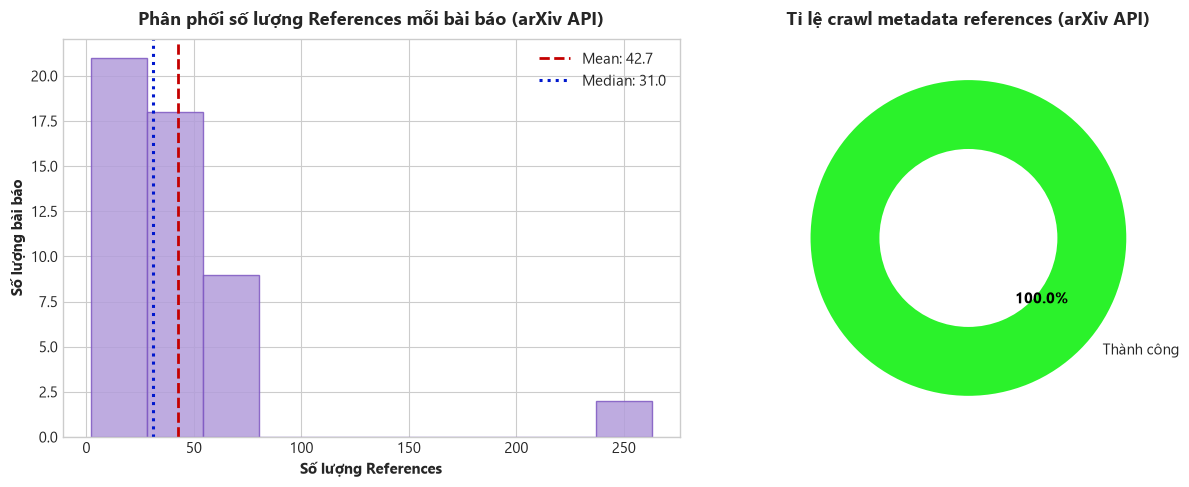

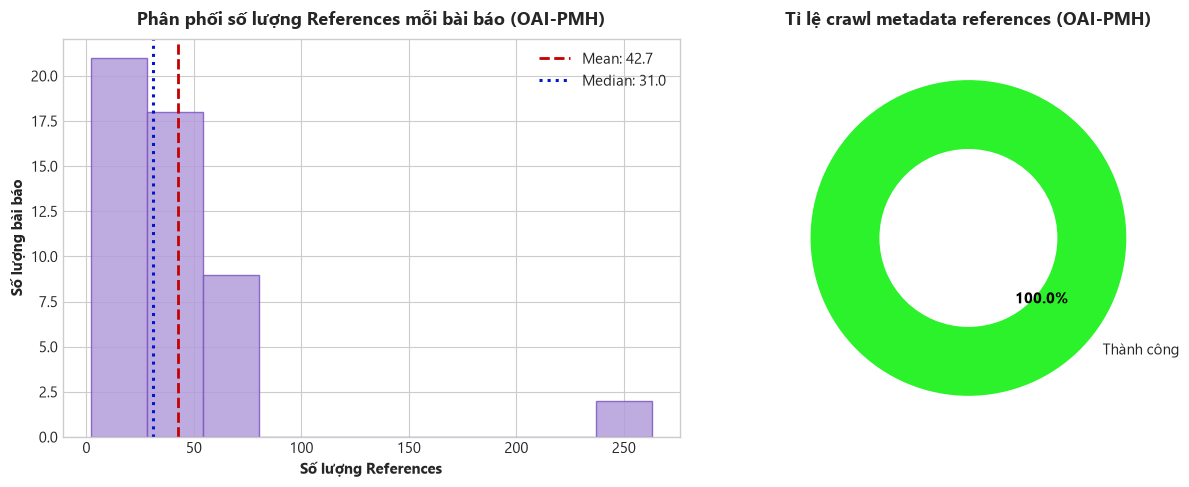

In [13]:
# Biểu đồ phân phối References (cột màu tím nhạt, mean đỏ đậm, median xanh dương đậm) và Tỷ lệ thành công
if not df_arxiv.empty:
    fig_arxiv = stat.plot_reference_stats(df_arxiv, title_suffix="arXiv API")
    plt.show()

if not df_oai.empty:
    fig_oai = stat.plot_reference_stats(df_oai, title_suffix="OAI-PMH")
    plt.show()

## 4. So Sánh Đối Chiếu Giữa 2 Phương Pháp Cào (arxiv_crawler vs oai_crawler)

Bảng tổng hợp đối chiếu trực tiếp giữa 2 phương pháp về cả 2 tiêu chí thống kê bắt buộc (căn lề trái toàn bộ nội dung).

In [14]:
df_comparison = stat.compare_crawlers_stats(df_arxiv, df_oai)
display(stat.format_table(df_comparison))

,Tiêu chí thống kê,arXiv API (arxiv_crawler),OAI-PMH (oai_crawler)
0,Tổng số phiên bản tải được,82 phiên bản,82 phiên bản
1,Kích thước trung bình trước khi lọc ảnh (KB),"2,549.37 KB","3,136.88 KB"
2,Kích thước trung bình sau khi lọc ảnh (KB),671.54 KB,677.81 KB
3,Tỷ lệ dung lượng tiết kiệm trung bình (%),57.94%,61.56%
4,Số lượng references trung bình / bài,42.66 refs/bài,42.66 refs/bài
5,Tỷ lệ crawl references thành công (%),100.00%,100.00%


## 5. Kết Luận và Nhận Xét

- **Về kích thước**: Việc loại bỏ hình ảnh giúp tiết kiệm đáng kể không gian lưu trữ (thường giảm từ 50% - 90% dung lượng thô), đồng thời loại bỏ các thành phần nhị phân không cần thiết cho quá trình phân tích cây cấu trúc phân cấp ở Milestone 2.
- **Về references**: Semantic Scholar API cung cấp độ bao phủ trích dẫn cao, phần lớn các bài báo đều có references đầy đủ kèm ArXiv ID, đóng vai trò là nền tảng dữ liệu đối sánh cho Milestone 3.
- **So sánh 2 phương pháp**: `arxiv_crawler` xử lý tốt các bài báo có kích thước vừa phải; trong khi `oai_crawler` thể hiện sự vượt trội khi xử lý các bài báo có kích thước lớn (>20 MB) nhờ cơ chế exponential backoff và retry tự động.